### Time Series Forecasting using LSTM-Generator

In [ ]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt 
import seaborn as sns 

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/S4248SM144NCEN.csv', index_col= 'DATE', parse_dates=True)
df.index.freq = 'MS'

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 328 entries, 1992-01-01 to 2019-04-01
Freq: MS
Data columns (total 1 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   S4248SM144NCEN  328 non-null    int64
dtypes: int64(1)
memory usage: 5.1 KB


In [ ]:
df.columns= ['Sales']

In [ ]:
df.head()

,Sales
DATE,
1992-01-01,3459
1992-02-01,3458
1992-03-01,4002
1992-04-01,4564
1992-05-01,4221


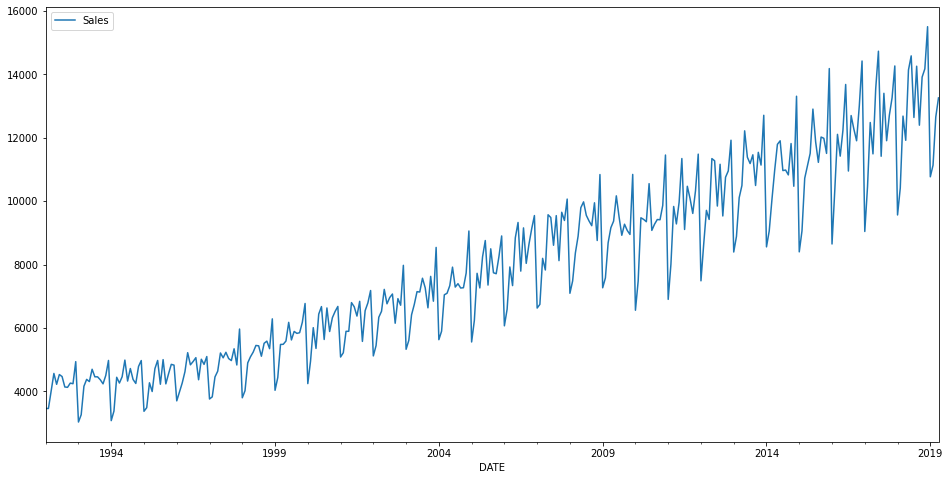

In [ ]:
df.plot(figsize=(16,8))

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [ ]:
result= seasonal_decompose(df['Sales'])

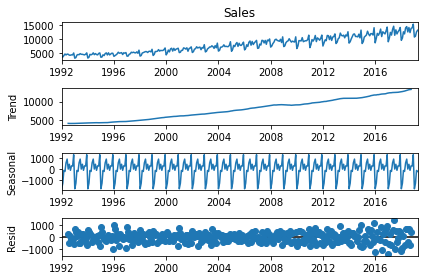

In [ ]:
result.plot();

In [ ]:
len(df)

328

In [ ]:
train = df.iloc[:316]
test= df.iloc[316:]

In [ ]:
test= test[0:12]

In [ ]:
test.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 12 entries, 2018-05-01 to 2019-04-01
Freq: MS
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Sales   12 non-null     int64
dtypes: int64(1)
memory usage: 192.0 bytes


In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
scaler = MinMaxScaler()

In [ ]:
scaler.fit(train)

MinMaxScaler()

In [ ]:
scaled_train = scaler.transform(train)

In [ ]:
scaled_test = scaler.transform(test) 

In [ ]:
from keras.preprocessing.sequence import TimeseriesGenerator

In [ ]:
len(scaled_train)

316

In [ ]:
from keras.models import Sequential
from keras.layers import Dense, LSTM

In [ ]:
n_input = 12
n_feature = 1

train_generator = TimeseriesGenerator(scaled_train,scaled_train,length=n_input, batch_size=1)

In [ ]:
model = Sequential()

model.add(LSTM(128,activation = 'relu', input_shape= (n_input, n_feature), return_sequences=True))
model.add(LSTM(128, activation='relu', return_sequences=True))
model.add(LSTM(128, activation='relu', return_sequences=False))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 12, 128)           66560     
                                                                 
 lstm_1 (LSTM)               (None, 12, 128)           131584    
                                                                 
 lstm_2 (LSTM)               (None, 128)               131584    
                                                                 
 dense (Dense)               (None, 1)                 129       
                                                                 
Total params: 329,857
Trainable params: 329,857
Non-trainable params: 0
_________________________________________________________________


In [ ]:
model.fit_generator(train_generator,epochs= 50)

Epoch 1/50


<ipython-input-26-cb9c59603b9c>:1: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  model.fit_generator(train_generator,epochs= 50)


304/304 [==============================] - 11s 22ms/step - loss: 0.0215
Epoch 2/50
304/304 [==============================] - 6s 20ms/step - loss: 0.0094
Epoch 3/50
304/304 [==============================] - 9s 31ms/step - loss: 0.0090
Epoch 4/50
304/304 [==============================] - 6s 20ms/step - loss: 0.0085
Epoch 5/50
304/304 [==============================] - 11s 36ms/step - loss: 0.0074
Epoch 6/50
304/304 [==============================] - 7s 24ms/step - loss: 0.0077
Epoch 7/50
304/304 [==============================] - 6s 19ms/step - loss: 0.0072
Epoch 8/50
304/304 [==============================] - 7s 24ms/step - loss: 0.0056
Epoch 9/50
304/304 [==============================] - 6s 19ms/step - loss: 0.0046
Epoch 10/50
304/304 [==============================] - 6s 20ms/step - loss: 0.0038
Epoch 11/50
304/304 [==============================] - 7s 22ms/step - loss: 0.0032
Epoch 12/50
304/304 [==============================] - 7s 24ms/step - loss: 0.0031
Epoch 13/50
304/304 [=

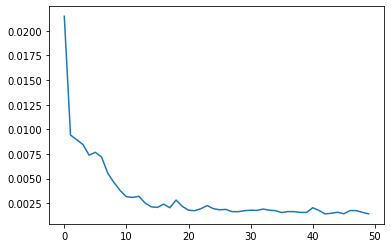

In [ ]:
my_loss= model.history.history['loss']
plt.plot(range(len(my_loss)),my_loss)

In [ ]:
first_eval_batch = scaled_train[-12:]

In [ ]:
first_eval_batch

array([[0.89870929],
       [1.        ],
       [0.71672793],
       [0.88648602],
       [0.75869732],
       [0.82742115],
       [0.87443371],
       [0.96025301],
       [0.5584238 ],
       [0.63116506],
       [0.82502778],
       [0.75972305]])

In [ ]:
first_eval_batch = first_eval_batch.reshape((1,n_input,n_feature))

In [ ]:
model.predict(first_eval_batch)

1/1 [==============================] - 0s 456ms/step


array([[0.954623]], dtype=float32)

In [ ]:
test_predictions = []


# last n_input points from the training set
first_eval_batch = scaled_train[-n_input:]
# reshape this to the format RNN wants (same format as TimeseriesGeneration)
current_batch = first_eval_batch.reshape((1,n_input,n_feature))

#how far into the future will I forecast?

for i in range(len(test)):
    
    # One timestep ahead of historical 12 points
    current_pred = model.predict(current_batch)[0]
    
    #store that prediction
    test_predictions.append(current_pred)
    
    # UPDATE current batch o include prediction
    current_batch = np.append(current_batch[:,1:,:],[[current_pred]], axis= 1)

1/1 [==============================] - 0s 19ms/step


In [ ]:
test_predictions

[array([0.954623], dtype=float32),
 array([1.0226289], dtype=float32),
 array([0.7924806], dtype=float32),
 array([0.9336096], dtype=float32),
 array([0.8099867], dtype=float32),
 array([0.8785188], dtype=float32),
 array([0.93015397], dtype=float32),
 array([0.99094117], dtype=float32),
 array([0.6099677], dtype=float32),
 array([0.713354], dtype=float32),
 array([0.874393], dtype=float32),
 array([0.84465945], dtype=float32)]

In [ ]:
true_predictions = scaler.inverse_transform(test_predictions)

In [ ]:
true_predictions

array([[14199.13428903],
       [14994.73554075],
       [12302.23039854],
       [13953.29876697],
       [12507.03452671],
       [13308.79167295],
       [13912.87124765],
       [14624.0207113 ],
       [10167.01222277],
       [11376.52834666],
       [13260.5235467 ],
       [12912.67087829]])

In [ ]:
test['Predictions']=true_predictions

In [ ]:
test.head()

,Sales,Predictions
DATE,,
2018-05-01,14138,14199.134289
2018-06-01,14583,14994.735541
2018-07-01,12640,12302.230399
2018-08-01,14257,13953.298767
2018-09-01,12396,12507.034527


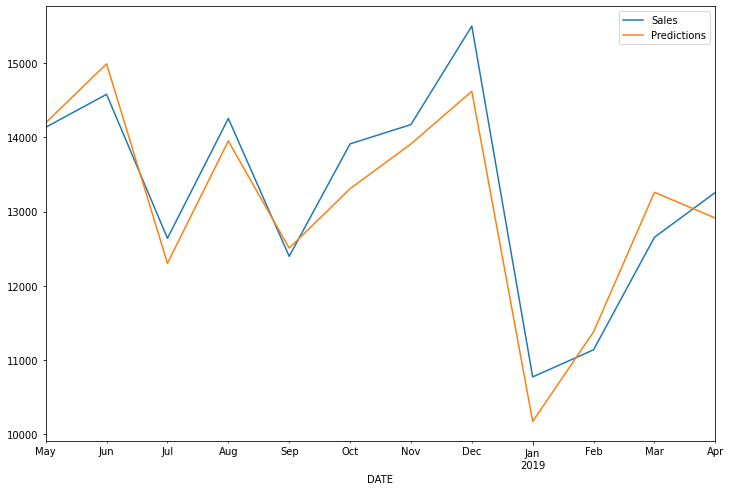

In [ ]:
test.plot(figsize=(12,8))

## LSTM For BitCoin Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
bit_data=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/bitstampUSD_1-min_data_2012-01-01_to_2019-03-13.csv")

In [ ]:
bit_data.head()

,Timestamp,Open,High,Low,Close,Volume_(BTC),Volume_(Currency),Weighted_Price
0,1325317920,4.39,4.39,4.39,4.39,0.455581,2.0,4.39
1,1325317980,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1325318040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1325318100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1325318160,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Adding a colum which is "date" and converting "Timestamp" columns to date form.

bit_data["date"]=pd.to_datetime(bit_data["Timestamp"],unit="s").dt.date
group=bit_data.groupby("date")
data=group["Close"].mean()

In [ ]:
data.shape

(2627,)

In [ ]:
data.isnull().sum()

0

In [ ]:
data.head()

date
2011-12-31    4.482500
2012-01-01    4.806667
2012-01-02    5.000000
2012-01-03    5.252500
2012-01-04    5.223333
Name: Close, dtype: float64

In [ ]:
# The goal is making a prediction of daily Close data. Prediction of "close" values of bitcoin data
# Taking the last 50 rows as test data and everything before that as train data

close_train=data.iloc[:len(data)-50]
close_test=data.iloc[len(close_train):]

In [ ]:
close_train.shape, close_test.shape

((2577,), (50,))

In [ ]:
# Feature scalling (set values between 0-1)

close_train=np.array(close_train)
close_train=close_train.reshape(close_train.shape[0],1)
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler(feature_range=(0,1))
close_scaled=scaler.fit_transform(close_train)

In [ ]:
# Choosing each 50 data as x-train and 51th as y-train 

timestep=50
x_train=[]
y_train=[]

for i in range(timestep,close_scaled.shape[0]):
    x_train.append(close_scaled[i-timestep:i,0])
    y_train.append(close_scaled[i,0])

x_train,y_train=np.array(x_train),np.array(y_train)
x_train=x_train.reshape(x_train.shape[0],x_train.shape[1],1) #reshaped for RNN
print("x_train shape= ",x_train.shape)
print("y_train shape= ",y_train.shape)

x_train shape=  (2527, 50, 1)
y_train shape=  (2527,)


In [ ]:
from sklearn.metrics import mean_absolute_error
from keras.models import Sequential
from keras.layers import Dense, LSTM, Dropout,Flatten

model=Sequential()
model.add(LSTM(10,input_shape=(None,1),activation="relu"))
model.add(Dense(1))
model.compile(loss="mean_squared_error",optimizer="adam")
model.fit(x_train,y_train,epochs=100,batch_size=32)

Epoch 1/10
79/79 [==============================] - 2s 14ms/step - loss: 0.0236
Epoch 2/10
79/79 [==============================] - 1s 16ms/step - loss: 0.0025
Epoch 3/10
79/79 [==============================] - 1s 14ms/step - loss: 8.5062e-04
Epoch 4/10
79/79 [==============================] - 1s 11ms/step - loss: 7.0110e-04
Epoch 5/10
79/79 [==============================] - 1s 11ms/step - loss: 6.3612e-04
Epoch 6/10
79/79 [==============================] - 1s 12ms/step - loss: 5.8676e-04
Epoch 7/10
79/79 [==============================] - 1s 10ms/step - loss: 5.3102e-04
Epoch 8/10
79/79 [==============================] - 1s 11ms/step - loss: 4.8331e-04
Epoch 9/10
79/79 [==============================] - 1s 11ms/step - loss: 4.2683e-04
Epoch 10/10
79/79 [==============================] - 1s 13ms/step - loss: 4.1046e-04


In [ ]:
inputs=data[len(data)-len(close_test)-timestep:]
inputs=inputs.values.reshape(-1,1)
inputs=scaler.transform(inputs)

In [ ]:
x_test=[]
for i in range(timestep,inputs.shape[0]):
    x_test.append(inputs[i-timestep:i,0])
x_test=np.array(x_test)
x_test=x_test.reshape(x_test.shape[0],x_test.shape[1],1)

In [ ]:
predicted_data=model.predict(x_test)
predicted_data=scaler.inverse_transform(predicted_data)

2/2 [==============================] - 1s 18ms/step


In [ ]:
data_test=np.array(close_test)
data_test=data_test.reshape(len(data_test),1)

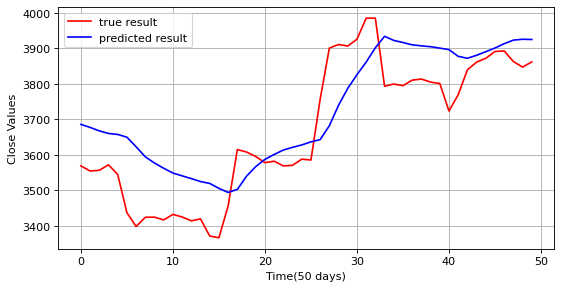

In [ ]:
plt.figure(figsize=(8,4), dpi=80, facecolor='w', edgecolor='k')
plt.plot(data_test,color="r",label="true result")
plt.plot(predicted_data,color="b",label="predicted result")
plt.legend()
plt.xlabel("Time(50 days)")
plt.ylabel("Close Values")
plt.grid(True)
plt.show()